# Event envelopes at 1.5σ and 2σ: implied equivalent depths

**Question:** Does defining stronger active envelope components produce cleaner
carrier fits and more concentrated apparent equivalent-depth distributions?

Daily 1990–2010 NOAA OLR and 34 Historical / 25 AMIP simulations use the same
filters, native calendars, preprocessing and raw active-component sinusoid fit.
The activity cutoff changes from 1.5σ to 2σ of the filtered OLR field; σ is
dataset- and wave-specific, measured excluding 150 days at each record end.
This is a common relative threshold, not a common absolute OLR amplitude. Active pixels are defined by the
**longitudinal Hilbert envelope**. Symmetry is projected over 20°S–20°N and
filtered OLR is averaged over northern 0–20° latitude before detecting components.

Components use eight-neighbor connections with periodic longitude, span at least
2 days and 10° longitude, and cannot touch the record endpoints. Each component
contributes one fitted signed K/frequency pair and its resting-state,
branch-specific apparent equivalent depth. All candidates remain in the source
catalogs, including failed fits and undefined depths. No background model or
significance selection is used. [Reproduction and audit](../scripts/codex_sigma2_events/README.md).


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.paths import DATA_DIR

ROOT = DATA_DIR / "event_threshold_comparison"
WAVES = ["Kelvin", "n1ERW", "MRG", "n0EIG", "n1WIG"]
LABELS = {"Kelvin": "Kelvin", "n1ERW": "n=1 ER", "MRG": "MRG", "n0EIG": "n=0 EIG", "n1WIG": "n=1 WIG"}
SOURCES = [("observations", "NOAA", "k"), ("historical", "Historical model mean", "C0"), ("amip", "AMIP model mean", "C1")]
SIGMA_STYLES = {1.5: "-", 2.0: "--"}
KEYS = ["model", "experiment", "member", "wave"]
audit = json.loads((ROOT / "audit.json").read_text())
summary = pd.read_csv(ROOT / "catalog_summary.csv")
histograms = pd.read_csv(ROOT / "depth_histograms.csv.gz")
assert audit["status"] == "complete" and len(summary) == 600
assert not summary.duplicated(KEYS + ["detection_sigma"]).any()
display(summary.groupby(["experiment", "detection_sigma"]).agg(
    catalogs=("wave", "size"), candidates=("candidates", "sum"),
    valid_depths=("valid_depths", "sum"), screened_events=("screened_events", "sum")))


catalogs  candidates  valid_depths  \
experiment   detection_sigma                                       
amip         1.5                   125      333451        331674   
             2.0                   125      276928        275592   
historical   1.5                   170      460222        457733   
             2.0                   170      385291        383480   
observations 1.5                     5       14386         14269   
             2.0                     5       11883         11783   

                              screened_events  
experiment   detection_sigma                   
amip         1.5                       120785  
             2.0                        75323  
historical   1.5                       169015  
             2.0                       103838  
observations 1.5                         5233  
             2.0                         3323

## Example Hovmöller: from the 2σ envelope to event depth

This NOAA Kelvin example is the existing quality-screened 2σ event whose
peak is nearest **1 July 2000**; ties use event ID. There is no depth selection,
and the example is illustrative rather than representative of the distribution.
The small cached slice was prepared on Levante with
`python scripts/codex_sigma2_events/prepare_hovmoller.py`.

The filter and detector are replayed on the **full 1990–2010 record** before
cropping. Replayed IDs, peaks and amplitudes match the saved catalog. The
magenta outline identifies the complete selected component. The cutoff applies
to $E=|q+i\mathcal H_\mathrm{lon}(q)|$, with $\sigma_q$ measured from the signed
filtered OLR field; it does not mean $q<-2\sigma_q$.

- The context plot compares the 1.5σ and 2σ envelope cutoffs over signed OLR.
- The close-up shows envelope amplitude and the chosen active component.
- The final plot overlays fitted negative-OLR crests **only within that component**.

The carrier is $q_\mathrm{fit}=b+A\cos[K\Delta\lambda-2\pi f\Delta t-\phi]$,
with longitude in radians and elapsed time in days. For Kelvin only,
$c=2\pi Rf/(86400K)$ and $h_\mathrm{eff}=c^2/g$, assuming zero background wind.
The cached parameters reproduce the saved component-fit R² and depth; the
catalog is not refitted for this illustration. Both positive and negative OLR
phases enter the fit because the envelope is unsigned. Depth comes from carrier
phase propagation, not the motion of the envelope boundary or its peak.

In [2]:
import xarray as xr
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

EXAMPLE_PATH = ROOT / "noaa_kelvin_sigma2_example.nc"
with xr.open_dataset(EXAMPLE_PATH, decode_timedelta=False) as source:
    example = source.load()
event = example.attrs
sigma_q = event["reference_sigma_W_m2"]
component = example.component_mask.values.astype(bool)
assert event["detection_sigma"] == 2 and event["wave_type"] == "Kelvin"
assert np.all(example.envelope.values[component] > 2 * sigma_q)
print(event["selection"])
print(f"Event {int(event['event_id'])}: peak {event['peak_time']}, {event['peak_lon_deg']:.1f}°E")
print(f"σ_q = {sigma_q:.3f} W m⁻²; 2σ_q = {2*sigma_q:.3f} W m⁻²; {component.sum()} active pixels")
display(pd.DataFrame([{
    "K": event["K_global"], "f [day⁻¹]": event["frequency_cpd"],
    "c [m s⁻¹]": event["phase_speed_m_s"], "h_eff [m]": event["h_eff_m"],
    "R²": event["weighted_r2"], "spatial cycles": event["spatial_cycles"],
    "temporal cycles": event["temporal_cycles"],
}]).round(3))

# Retain the entire component plus 3 days and 12 longitude grid cells each side.
rows, columns = np.where(component)
zoom = example.isel(
    time=slice(max(0, rows.min()-3), min(example.sizes["time"], rows.max()+4)),
    lon=slice(max(0, columns.min()-12), min(example.sizes["lon"], columns.max()+13)),
)
assert int(zoom.component_mask.sum()) == int(component.sum())
peak_date = mdates.date2num(np.datetime64(event["peak_time"]))
OLR_LIMIT = 3 * sigma_q  # Identical signed-OLR color range in context and close-up.


Existing quality-screened event nearest 2000-07-01; ties use event_id; no depth selection
Event 1650: peak 2000-06-26T12:00:00.000000000, 168.5°E
σ_q = 5.338 W m⁻²; 2σ_q = 10.675 W m⁻²; 373 active pixels


,K,f [day⁻¹],c [m s⁻¹],h_eff [m],R²,spatial cycles,temporal cycles
0,6.548,0.145,10.225,10.662,0.909,0.928,1.59


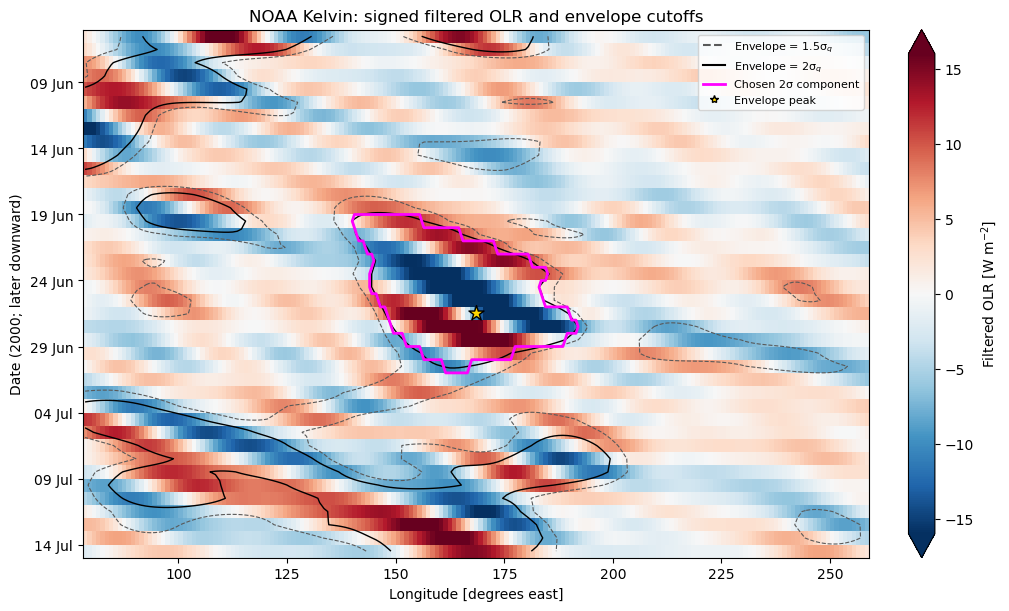

In [3]:
dates = mdates.date2num(example.time.values)
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
mesh = ax.pcolormesh(example.lon.values, dates, example.filtered_olr.values,
                     shading="auto", cmap="RdBu_r", vmin=-OLR_LIMIT, vmax=OLR_LIMIT)
ax.contour(example.lon.values, dates, example.envelope.values / sigma_q,
           levels=[1.5, 2.0], colors=[".35", "k"],
           linestyles=["--", "-"], linewidths=[.8, 1.0])
ax.contour(example.lon.values, dates, component.astype(float),
           levels=[.5], colors=["magenta"], linewidths=2)
ax.scatter(event["peak_lon_deg"], peak_date, marker="*", s=130,
           color="gold", edgecolor="k", zorder=5)
ax.yaxis_date()
ax.yaxis.set_major_locator(mdates.DayLocator(interval=5))
ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.invert_yaxis()
ax.set(xlabel="Longitude [degrees east]", ylabel="Date (2000; later downward)",
       title="NOAA Kelvin: signed filtered OLR and envelope cutoffs")
fig.colorbar(mesh, ax=ax, label="Filtered OLR [W m$^{-2}$]", extend="both")
ax.legend(handles=[
    Line2D([], [], color=".35", linestyle="--", label="Envelope = 1.5σ$_q$"),
    Line2D([], [], color="k", label="Envelope = 2σ$_q$"),
    Line2D([], [], color="magenta", linewidth=2, label="Chosen 2σ component"),
    Line2D([], [], color="gold", marker="*", markeredgecolor="k", linestyle="none", label="Envelope peak"),
], loc="upper right", fontsize=8)
plt.show()


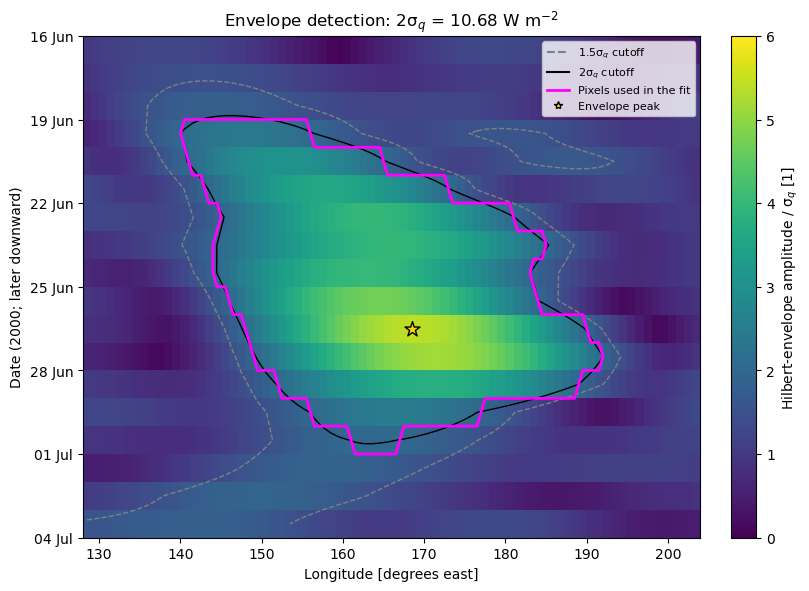

In [4]:
zoom_dates = mdates.date2num(zoom.time.values)
zoom_component = zoom.component_mask.values.astype(bool)
fig, ax = plt.subplots(figsize=(8, 5.8), layout="constrained")
mesh = ax.pcolormesh(zoom.lon.values, zoom_dates, zoom.envelope.values / sigma_q,
                     shading="auto", cmap="viridis", vmin=0, vmax=6)
ax.contour(zoom.lon.values, zoom_dates, zoom.envelope.values / sigma_q,
           levels=[1.5, 2.0], colors=[".5", "k"], linestyles=["--", "-"], linewidths=1)
ax.contour(zoom.lon.values, zoom_dates, zoom_component.astype(float),
           levels=[.5], colors=["magenta"], linewidths=2)
ax.scatter(event["peak_lon_deg"], peak_date, marker="*", s=130,
           color="gold", edgecolor="k", zorder=5)
ax.yaxis_date()
ax.yaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.invert_yaxis()
ax.set(xlabel="Longitude [degrees east]", ylabel="Date (2000; later downward)",
       title=f"Envelope detection: 2σ$_q$ = {2*sigma_q:.2f} W m$^{{-2}}$")
fig.colorbar(mesh, ax=ax, label="Hilbert-envelope amplitude / σ$_q$ [1]")
ax.legend(handles=[
    Line2D([], [], color=".5", linestyle="--", label="1.5σ$_q$ cutoff"),
    Line2D([], [], color="k", label="2σ$_q$ cutoff"),
    Line2D([], [], color="magenta", linewidth=2, label="Pixels used in the fit"),
    Line2D([], [], color="gold", marker="*", markeredgecolor="k", linestyle="none", label="Envelope peak"),
], loc="upper right", fontsize=8)
plt.show()


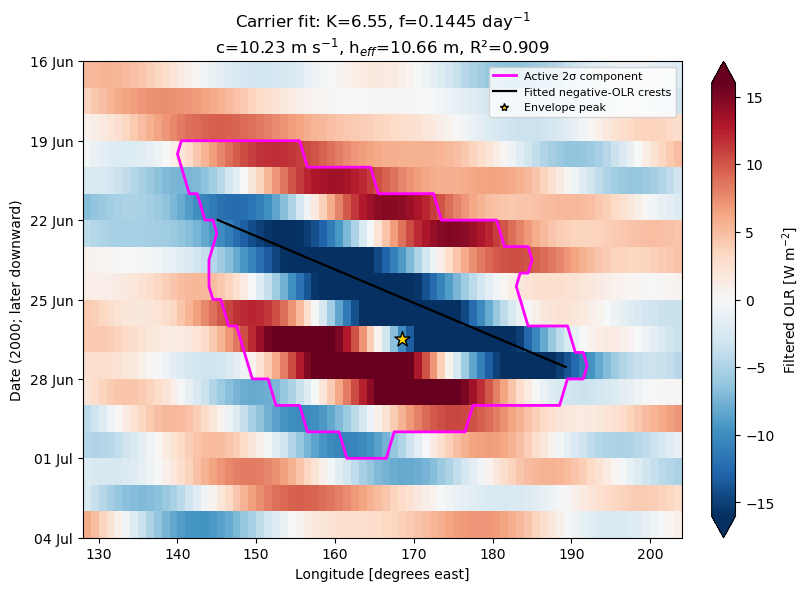

In [5]:
phase = (
    event["K_global"] * np.deg2rad(zoom.lon.values - event["peak_lon_deg"])[None, :]
    - 2*np.pi*event["frequency_cpd"] * zoom.lag_day.values[:, None]
    - event["phase_rad"]
)
# cos(phase) = -1 gives fitted negative-OLR crests. Mask every contour outside
# the selected component; neither nearby events nor the context enter this fit.
phase_on_component = np.ma.masked_where(~zoom_component, phase)
first_crest = int(np.ceil((phase_on_component.min()-np.pi)/(2*np.pi)))
last_crest = int(np.floor((phase_on_component.max()-np.pi)/(2*np.pi)))
crest_levels = np.pi + 2*np.pi*np.arange(first_crest, last_crest+1)
fig, ax = plt.subplots(figsize=(8, 5.8), layout="constrained")
mesh = ax.pcolormesh(zoom.lon.values, zoom_dates, zoom.filtered_olr.values,
                     shading="auto", cmap="RdBu_r", vmin=-OLR_LIMIT, vmax=OLR_LIMIT)
ax.contour(zoom.lon.values, zoom_dates, zoom_component.astype(float),
           levels=[.5], colors=["magenta"], linewidths=2)
ax.contour(zoom.lon.values, zoom_dates, phase_on_component,
           levels=crest_levels, colors=["k"], linewidths=1.6, linestyles="-")
ax.scatter(event["peak_lon_deg"], peak_date, marker="*", s=130,
           color="gold", edgecolor="k", zorder=5)
ax.yaxis_date()
ax.yaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.yaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.invert_yaxis()
ax.set(xlabel="Longitude [degrees east]", ylabel="Date (2000; later downward)",
       title=(f"Carrier fit: K={event['K_global']:.2f}, f={event['frequency_cpd']:.4f} day$^{{-1}}$\n"
              f"c={event['phase_speed_m_s']:.2f} m s$^{{-1}}$, h$_{{eff}}$={event['h_eff_m']:.2f} m, R²={event['weighted_r2']:.3f}"))
fig.colorbar(mesh, ax=ax, label="Filtered OLR [W m$^{-2}$]", extend="both")
ax.legend(handles=[
    Line2D([], [], color="magenta", linewidth=2, label="Active 2σ component"),
    Line2D([], [], color="k", linewidth=1.6, label="Fitted negative-OLR crests"),
    Line2D([], [], color="gold", marker="*", markeredgecolor="k", linestyle="none", label="Envelope peak"),
], loc="upper right", fontsize=8)
plt.show()


## NOAA: counts, fit support and implied depths

The valid-depth subset requires a successful fit and a positive depth on the
assigned dispersion branch. The screened subset additionally uses the unchanged
catalog criteria: no search-grid boundary, R² ≥ 0.3, at least half a sampled
spatial cycle and one temporal cycle. R² is computed on the component's active
pixels. Raising the activity threshold changes those pixels and the population.


In [6]:
columns = ["candidates", "valid_depths", "screened_events", "screened_fraction",
           "median_fit_r2", "median_spatial_cycles", "median_temporal_cycles",
           "valid_h_median_m", "screened_h_median_m", "valid_h_above_200_fraction"]
noaa_table = summary.loc[summary.experiment.eq("observations")].set_index(["wave", "detection_sigma"])
display(noaa_table[columns].sort_index().round(3))


candidates  valid_depths  screened_events  \
wave   detection_sigma                                              
Kelvin 1.5                    2897          2897              767   
       2.0                    2573          2573              530   
MRG    1.5                    2964          2847              806   
       2.0                    2389          2289              475   
n0EIG  1.5                    3660          3660             1409   
       2.0                    2989          2989              901   
n1ERW  1.5                    1029          1029              215   
       2.0                     887           887              117   
n1WIG  1.5                    3836          3836             2036   
       2.0                    3045          3045             1300   

                        screened_fraction  median_fit_r2  \
wave   detection_sigma                                     
Kelvin 1.5                          0.265          0.976   
       2.0                          0.206          0.984   
MRG    1.5                          0.272          0.980   
       2.0                          0.199          0.990   
n0EIG  1.5                          0.385          0.981   
       2.0                          0.301          0.990   
n1ERW  1.5                          0.209          0.976   
       2.0                          0.132          0.984   
n1WIG  1.5                          0.531          0.981   
       2.0                          0.427          0.992   

                        median_spatial_cycles  median_temporal_cycles  \
wave   detection_sigma                                                  
Kelvin 1.5                              0.631                   0.606   
       2.0                              0.570                   0.517   
MRG    1.5                              0.582                   0.640   
       2.0                              0.506                   0.503   
n0EIG  1.5                              0.536                   0.927   
       2.0                              0.478                   0.814   
n1ERW  1.5                              0.541                   0.573   
       2.0                              0.501                   0.500   
n1WIG  1.5                              0.613                   1.181   
       2.0                              0.529                   1.020   

                        valid_h_median_m  screened_h_median_m  \
wave   detection_sigma                                          
Kelvin 1.5                        15.219               17.200   
       2.0                        14.820               17.531   
MRG    1.5                        54.022               18.317   
       2.0                        54.038               18.989   
n0EIG  1.5                         8.690                8.073   
       2.0                         8.791                8.270   
n1ERW  1.5                        20.485               22.089   
       2.0                        19.980               23.162   
n1WIG  1.5                         7.729                7.312   
       2.0                         7.865                7.330   

                        valid_h_above_200_fraction  
wave   detection_sigma                              
Kelvin 1.5                                   0.000  
       2.0                                   0.000  
MRG    1.5                                   0.246  
       2.0                                   0.233  
n0EIG  1.5                                   0.000  
       2.0                                   0.000  
n1ERW  1.5                                   0.000  
       2.0                                   0.000  
n1WIG  1.5                                   0.000  
       2.0                                   0.000

## Matched source/wave comparisons

Each row pairs the same model, experiment, member and wave family across
thresholds. Event IDs are never joined across thresholds: raising the cutoff
can split, shorten or remove a component. The table reports NOAA's direct
changes and model-wise median changes for the two model ensembles.


In [7]:
baseline = summary.loc[summary.detection_sigma.eq(1.5)].set_index(KEYS)
stronger = summary.loc[summary.detection_sigma.eq(2.)].set_index(KEYS).reindex(baseline.index)
assert len(baseline) == len(stronger) == 300
paired = pd.DataFrame(index=baseline.index)
for column in ["candidates", "valid_depths", "screened_events"]:
    paired[column + "_change_pct"] = 100 * (stronger[column] / baseline[column].replace(0, np.nan) - 1)
paired["screened_fraction_change_pp"] = 100 * (stronger.screened_fraction - baseline.screened_fraction)
paired["median_r2_change"] = stronger.median_fit_r2 - baseline.median_fit_r2
paired["median_temporal_cycles_change"] = stronger.median_temporal_cycles - baseline.median_temporal_cycles
paired["valid_h_median_change_m"] = stronger.valid_h_median_m - baseline.valid_h_median_m
paired["valid_h_iqr_change_m"] = (stronger.valid_h_p75_m - stronger.valid_h_p25_m) - (baseline.valid_h_p75_m - baseline.valid_h_p25_m)
display(paired.groupby(["experiment", "wave"]).median().round(3))


candidates_change_pct  valid_depths_change_pct  \
experiment   wave                                                     
amip         Kelvin                -13.082                  -13.082   
             MRG                   -16.059                  -16.168   
             n0EIG                 -17.491                  -17.491   
             n1ERW                 -11.152                  -11.152   
             n1WIG                 -18.496                  -18.496   
historical   Kelvin                -12.882                  -12.868   
             MRG                   -14.887                  -14.545   
             n0EIG                 -17.481                  -17.481   
             n1ERW                 -11.632                  -11.632   
             n1WIG                 -17.483                  -17.483   
observations Kelvin                -11.184                  -11.184   
             MRG                   -19.399                  -19.600   
             n0EIG                 -18.333                  -18.333   
             n1ERW                 -13.800                  -13.800   
             n1WIG                 -20.620                  -20.620   

                     screened_events_change_pct  screened_fraction_change_pp  \
experiment   wave                                                              
amip         Kelvin                     -40.814                       -8.512   
             MRG                        -43.726                      -10.477   
             n0EIG                      -32.397                       -7.294   
             n1ERW                      -51.980                       -9.205   
             n1WIG                      -34.734                       -8.739   
historical   Kelvin                     -40.629                       -8.072   
             MRG                        -43.972                      -11.091   
             n0EIG                      -34.789                       -8.104   
             n1ERW                      -52.440                      -10.481   
             n1WIG                      -34.774                      -10.745   
observations Kelvin                     -30.900                       -5.877   
             MRG                        -41.067                       -7.310   
             n0EIG                      -36.054                       -8.353   
             n1ERW                      -45.581                       -7.704   
             n1WIG                      -36.149                      -10.383   

                     median_r2_change  median_temporal_cycles_change  \
experiment   wave                                                      
amip         Kelvin             0.009                         -0.084   
             MRG                0.010                         -0.131   
             n0EIG              0.008                         -0.113   
             n1ERW              0.012                         -0.098   
             n1WIG              0.009                         -0.133   
historical   Kelvin             0.009                         -0.091   
             MRG                0.010                         -0.142   
             n0EIG              0.008                         -0.128   
             n1ERW              0.012                         -0.112   
             n1WIG              0.009                         -0.178   
observations Kelvin             0.008                         -0.089   
             MRG                0.010                         -0.137   
             n0EIG              0.009                         -0.112   
             n1ERW              0.008                         -0.073   
             n1WIG              0.010                         -0.161   

                     valid_h_median_change_m  valid_h_iqr_change_m  
experiment   wave                                                   
amip         Kelvin                   -0.266                -0.925  
             MRG    

## Depth distributions: all successful, dispersion-valid fits

Each curve counts events, with 5 m bins. Densities divide by **all** selected
events, including those above the 200 m display limit, so a curve need not
integrate to one within the plot. The light gray band marks 10–80 m without
restricting detection or fitting. Each model is normalized separately before
forming an equally weighted ensemble mean. Solid lines use 1.5σ; dashed lines
use 2σ. Missing depth estimates are counted in the audit tables above.


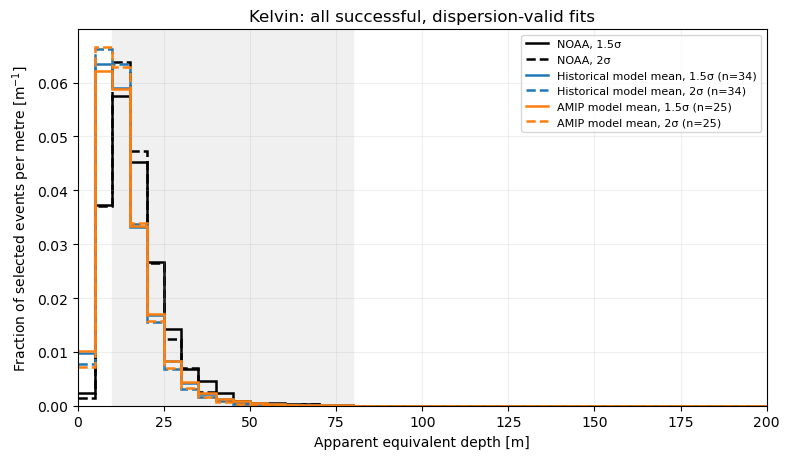

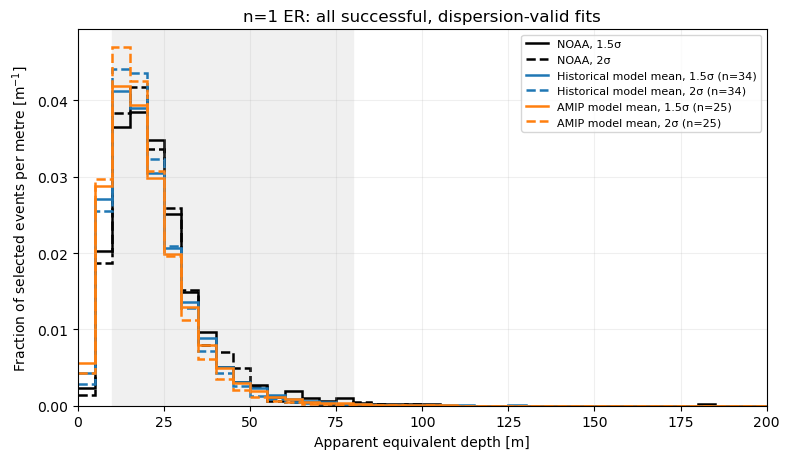

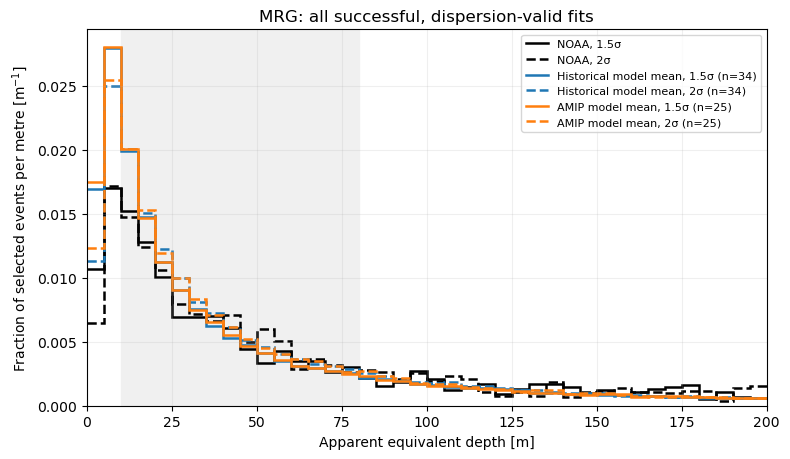

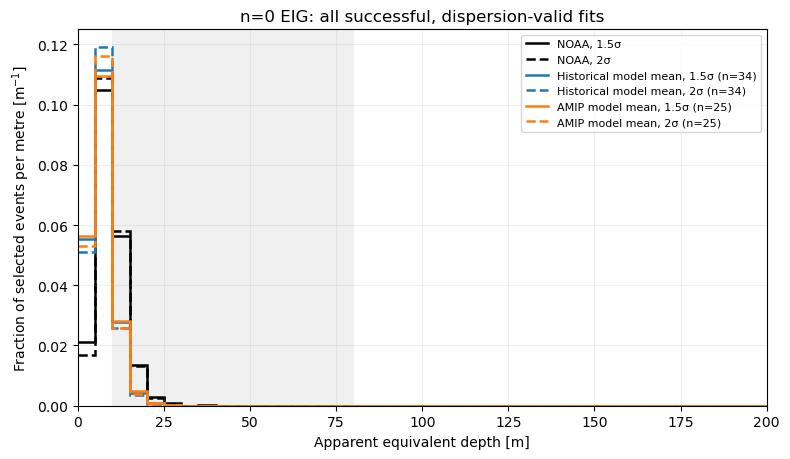

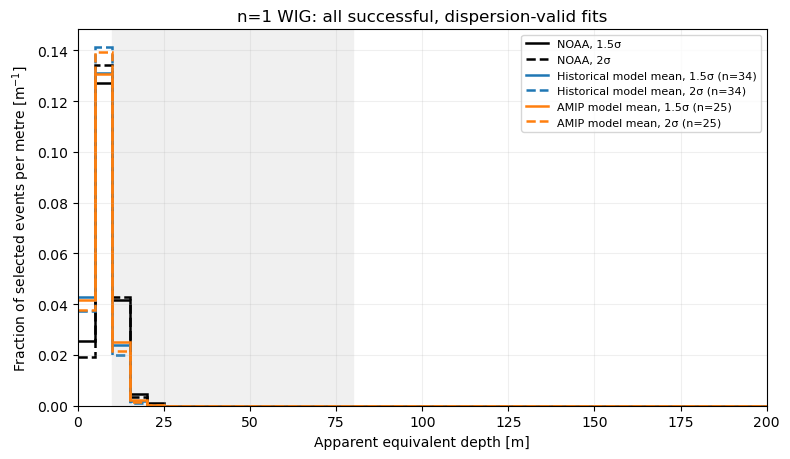

In [8]:
selection_title = "all successful, dispersion-valid fits"
selection = 'valid'
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(8, 4.7))
    for experiment, source_label, color in SOURCES:
        for sigma, linestyle in SIGMA_STYLES.items():
            part = histograms.loc[
                histograms.experiment.eq(experiment) & histograms.wave.eq(wave)
                & histograms.detection_sigma.eq(sigma) & histograms.selection.eq(selection)
                & histograms.selected_events.gt(0)
            ]
            if part.empty:
                print(f"No {selection} depths: {experiment}, {wave}, {sigma} sigma")
                continue
            density = part.groupby("lower_m").density_per_m.mean().sort_index()
            model_count = part[["model", "member"]].drop_duplicates().shape[0]
            label = f"{source_label}, {sigma:g}σ"
            if experiment != "observations":
                label += f" (n={model_count})"
            ax.stairs(density, np.arange(0., 200.1, 5.), baseline=None,
                      color=color, linestyle=linestyle, linewidth=1.8, label=label)
    ax.axvspan(10, 80, color=".94", zorder=-2)
    ax.set(xlim=(0, 200), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
           ylabel="Fraction of selected events per metre [m$^{-1}$]",
           title=f"{LABELS[wave]}: {selection_title}")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()


## Depth distributions with the existing fit-quality screen

This additional view keeps the same screen at both thresholds. Its denominator
is each record's full screened population, including depths above 200 m. The
legend states the number of contributing models; a source with no screened
events has no defined normalized distribution.


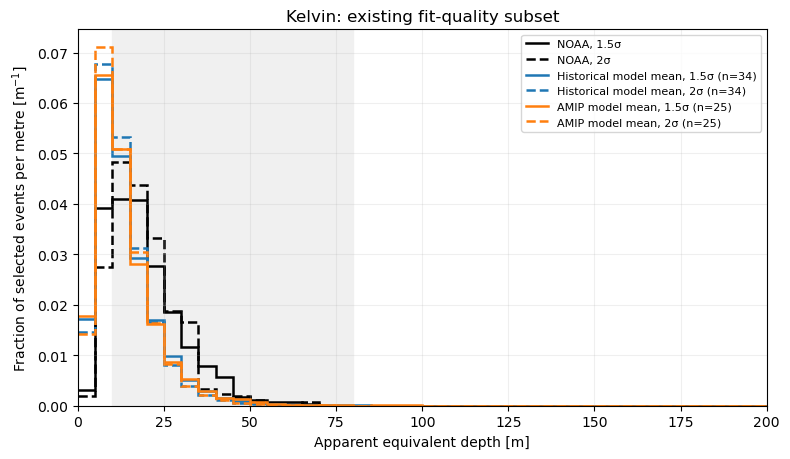

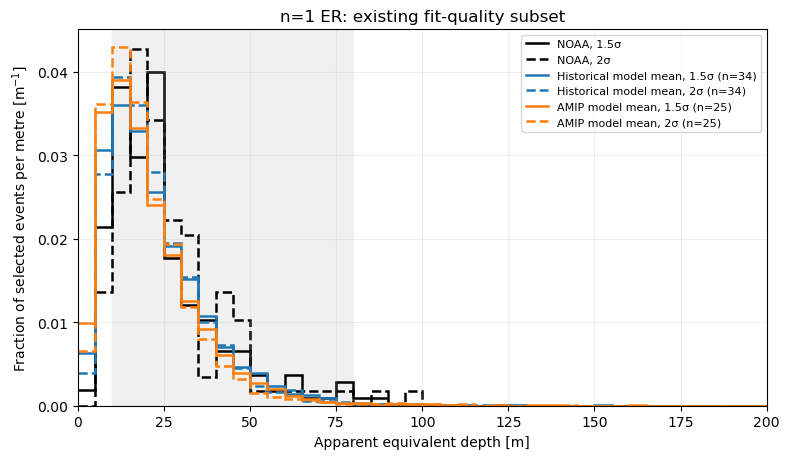

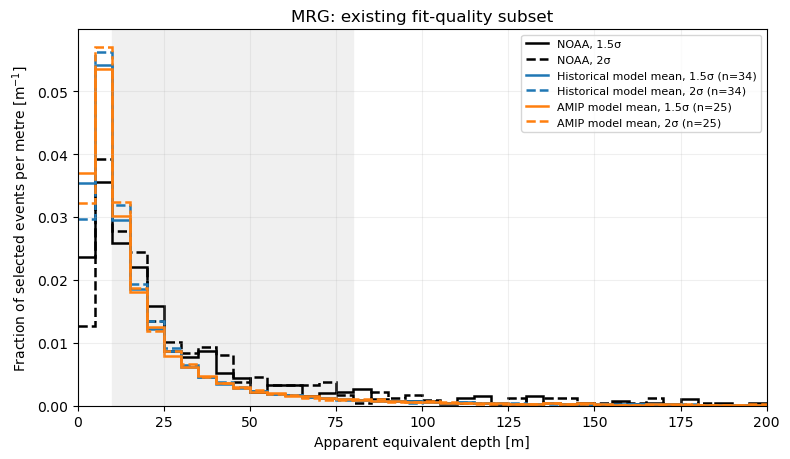

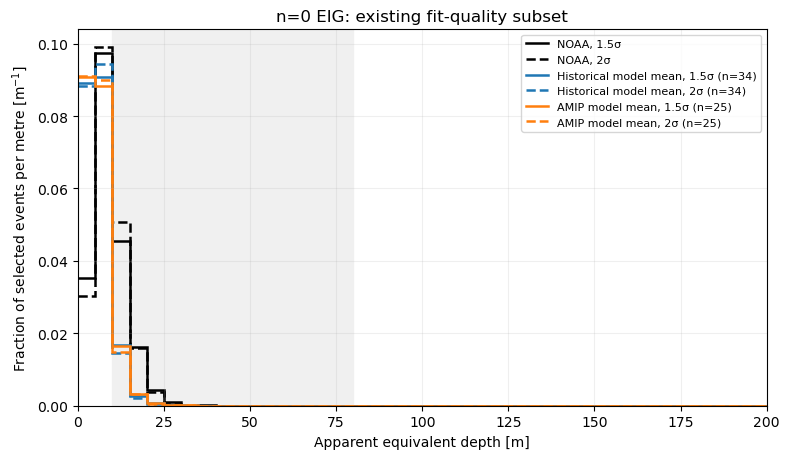

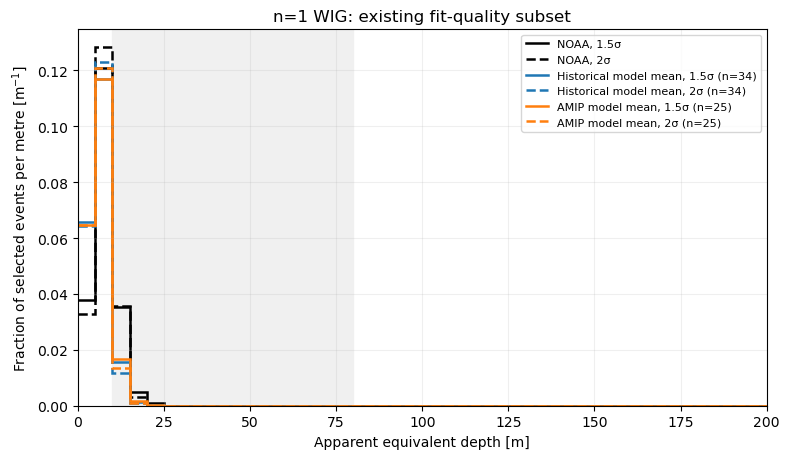

In [9]:
selection_title = "existing fit-quality subset"
selection = 'screened'
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(8, 4.7))
    for experiment, source_label, color in SOURCES:
        for sigma, linestyle in SIGMA_STYLES.items():
            part = histograms.loc[
                histograms.experiment.eq(experiment) & histograms.wave.eq(wave)
                & histograms.detection_sigma.eq(sigma) & histograms.selection.eq(selection)
                & histograms.selected_events.gt(0)
            ]
            if part.empty:
                print(f"No {selection} depths: {experiment}, {wave}, {sigma} sigma")
                continue
            density = part.groupby("lower_m").density_per_m.mean().sort_index()
            model_count = part[["model", "member"]].drop_duplicates().shape[0]
            label = f"{source_label}, {sigma:g}σ"
            if experiment != "observations":
                label += f" (n={model_count})"
            ax.stairs(density, np.arange(0., 200.1, 5.), baseline=None,
                      color=color, linestyle=linestyle, linewidth=1.8, label=label)
    ax.axvspan(10, 80, color=".94", zorder=-2)
    ax.set(xlim=(0, 200), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
           ylabel="Fraction of selected events per metre [m$^{-1}$]",
           title=f"{LABELS[wave]}: {selection_title}")
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()


## Interpretation

The audit passed for all 600 catalogs, requiring each source/wave recipe to
differ only in its detection/peak threshold. Across this fixed cohort, detected
candidates decrease from 808,059 to 674,102 (16.6%), while the existing
quality-screened subset decreases from 295,033 to 182,484 (38.1%). These totals
pool different source populations; the comparisons above pair each source/wave.

Median component-fit R² increases and median sampled temporal cycles decrease
in all 300 paired source/wave comparisons. The screened fraction decreases in
299 of 300. The all-valid depth interquartile range narrows in 281 of 300,
but a narrower distribution and higher R² do not establish better physical
depth estimates when the fitted support is also shrinking.

NOAA's all-valid median depths at 2σ are 14.8 m (Kelvin), 20.0 m (ER),
54.0 m (MRG), 8.8 m (EIG), and 7.9 m (WIG); each changes by less than
0.6 m from 1.5σ. In the models, paired median-depth changes are generally
below 1 m except MRG: the median change across models is +3.5 m in Historical
and +2.9 m in AMIP. These are descriptive changes, not significance tests.

MRG remains especially sensitive to fit quality: NOAA's 2σ median is 54.0 m
for all valid fits but 19.0 m for the screened subset, and 23.3% of all valid
MRG depths exceed the 200 m display limit. Its broad tail is retained in the
histogram denominator. The resting-background, assigned-branch inversion and
the available carrier cycles remain limitations; this threshold experiment
alone does not establish cleaner physical depths.

Full threshold-specific catalogs are identified by `catalog` and `run_id` in
`catalog_summary.csv`; all candidates remain available for further inspection.
There is no background calibration or significance selection. No standalone
figure files are written by this notebook.
